# 关于模型调用的invoke的使用


## 1.invoke的传参


### 1.1 文本输入

举例

In [1]:
import os

from pydantic import SecretStr
from dotenv import load_dotenv
from langchain_openrouter import ChatOpenRouter

# 1、读取.env配置文件中的信息。相关的环境变量以.env文件优先
load_dotenv(verbose=True)
OPENROUTER_API_KEY=SecretStr(os.getenv("OPENROUTER_API_KEY")or"")

# 2、模型的初始化
model=ChatOpenRouter(
    model="dots-studio/dots-3-note-preview:free",
    api_key=OPENROUTER_API_KEY,

)
# 3、模型的调用
response=model.invoke("请用一句话介绍你自己，包括你是哪个公司的，哪个国家的").content
print(response)



我是 dots，来自中国小红书 Dots Studio 的 AI 大模型。


### 1.2字典列表messages
创建字典列表组成消息。一条消息通常包含 role（角色） 、 content（内容） 等信息。
✅适用场景：可以设置系统提示，表达多轮对话历史，JSON 兼容，易于序列化和网络传输，生产环境
推荐。
| 角色| 英文 | 作用| 示例|
|-----|-----|-----|-----|
| system  | System | 设定 AI 的行为、角色、规则  |"你是一个专业的 Python 导师"|
| user  | Human/User  | 用户的输入/问题  |"什么是装饰器？"|
| assistant  | AI/Assistant  | AI 的历史回复（用于对话上下文）  |"装饰器是一种设计模式..."|


举例1

In [12]:
messages=[
    {"role":"system","content":"你是一个专业的数学老师"},
    {"role":"user","content":"帮我解释一下斐波那契数列"},

]
response=model.invoke(messages).content
print(response)



好的，我来帮你梳理一下斐波那契数列，从基础概念到一些有趣的性质。

---

### 一、基本定义

斐波那契数列（Fibonacci sequence）是一个非常简单的递推数列：

- 第 1 项：F₁ = 1
- 第 2 项：F₂ = 1
- 从第 3 项开始，每一项等于前两项之和：Fₙ = Fₙ₋₁ + Fₙ₋₂（n ≥ 3）

写成数列就是：

**1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, …**

---

### 二、直观理解

你可以把它想象成“一对兔子每月繁殖一对新兔子”的理想模型：

- 第 1 个月：1 对兔子
- 第 2 个月：1 对兔子（还没成熟）
- 第 3 个月：原来的 1 对生了 1 对 → 共 2 对
- 第 4 个月：原来的生了 1 对，新兔子还没成熟 → 共 3 对
- 第 5 个月：两对都生 → 共 5 对
- ……

这个模型正是斐波那契本人在《算盘书》中提出的问题背景，数列也因此得名。

---

### 三、通项公式（比内公式）

虽然递推很好理解，但有时候我们想直接算第 n 项。这时可以用**比内公式**（Binet's formula）：

\[
F_n = \frac{\varphi^n - \psi^n}{\sqrt{5}}
\]

其中：
- \(\varphi = \frac{1+\sqrt{5}}{2} \approx 1.618\)（黄金比例）
- \(\psi = \frac{1-\sqrt{5}}{2} \approx -0.618\)

因为 \(|\psi| < 1\)，当 n 较大时，\(\psi^n\) 会迅速趋近于 0，所以：

\[
F_n \approx \frac{\varphi^n}{\sqrt{5}}
\]

这解释了为什么斐波那契数列和黄金比例关系密切。

---

### 四、一些有趣的性质

1. **相邻两项的比值趋近于黄金比例**  
   比如 8/5 = 1.6，13/8 = 1.625，21/13 ≈ 1.615，越往后越接近 1.618。

2. **与自然界的联系**  
   - 松果鳞片、菠萝表皮的螺旋数常常是 8 和 13，或 21 和 34，都是斐波那契数。
   - 向日葵花盘、 pinecone 的螺旋排

举例2 多轮对话(带历史)

In [13]:
messages = [
{"role":"system","content":"你是一个专业的数学老师。"},
{"role":"user","content":"2 + 3 * 2 = ？"},
{"role":"assistant","content":"8"},
{"role":"user","content":"我刚才问了什么问题？"}
]

response=model.invoke(messages).content
print(response)



你刚才问的是：2 + 3 * 2 等于多少？


举例3 如果不传递历史，AI会“失忆“

In [14]:
messages1 = [
{"role": "system", "content": "你是一个非常友好的AI助手"},
{"role": "user", "content": "你好，我叫小明"},
]
# 第一次对话
response1 = model.invoke(messages1)
# 打印响应
print(f"AI的回复1：{response1.content}")
messages2 = [
{"role": "user", "content": "我叫什么名字？"}
]
# 第二次对话
response2 = model.invoke(messages2)
# 打印响应
print(f"AI的回复2：{response2.content}")

AI的回复1：

你好小明，很高兴认识你。今天想聊点什么？
AI的回复2：

我目前还不知道你的名字呢，刚聊起来，还没来得及问。你叫什么呀？


作为对比，我们将历史传递

In [15]:
conversation = [
{"role": "system", "content": "你是一个非常友好的AI助手"},
{"role": "user", "content": "你好，我叫小明"}
]
# 第一次对话
response1 = model.invoke(conversation)
# 打印响应
print(f"AI的回复1：{response1.content}")
# 添加记忆
conversation.append({"role": "assistant", "content": response1.content})
conversation.append({"role": "user", "content": "我叫什么名字？"})
# 第二次对话
response2 = model.invoke(conversation)
print(f"AI的回复2：{response2.content}")

AI的回复1：

你好小明，很高兴认识你。
AI的回复2：

你叫小明。


### 1.3 消息对象列表的传递
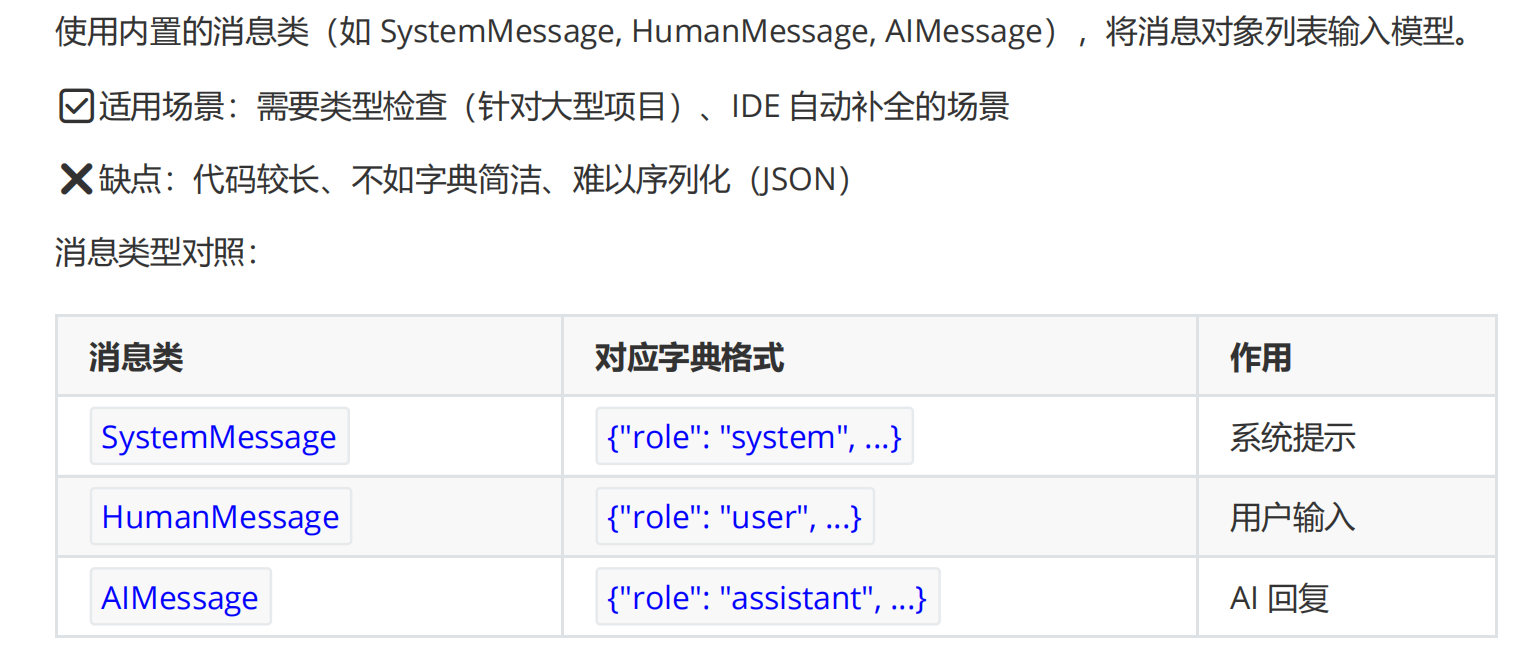
举例1

In [17]:
from langchain_core.messages import HumanMessage,SystemMessage

message=[
    SystemMessage(content="你是一个音乐老师"),
    HumanMessage(content="帮我介绍一下常见的和弦"),
]
response=model.invoke(message).content
print(response)



好的，非常乐意为您介绍音乐中最常见和基础的和弦。无论您是弹钢琴、吉他，还是单纯想提升音乐素养，掌握这些和弦都是至关重要的第一步。

我们将从最核心的**三和弦**开始，然后扩展到更丰富的**七和弦**。

---

### 一、 核心基础：三和弦

三和弦是所有和弦的基石，由三个音构成，按三度关系叠置。

#### 1. 大三和弦
- **构成**：根音 + 大三度 + 纯五度
- **音响效果**：明亮、欢快、积极，具有“解决”感。
- **例子**：
    - **C大三和弦**：C - E - G （C到E是大三度，E到G是小三度，整体是“大三度+小三度”）
    - 在流行音乐中极为常见，如《Let It Be》的C - G - Am - F。

#### 2. 小三和弦
- **构成**：根音 + 小三度 + 纯五度
- **音响效果**：暗淡、忧伤、内省，与大三和弦形成鲜明对比。
- **例子**：
    - **C小三和弦**：C - Eb - G （C到Eb是小三度，Eb到G是大三度，整体是“小三度+大三度”）
    - 常用于表达情感深度，如《Hey Jude》开头的D - Dmaj7 - G - D。

#### 3. 减三和弦
- **构成**：根音 + 小三度 + 减五度
- **音响效果**：紧张、不稳定、充满悬念，通常需要解决到更稳定的和弦。
- **例子**：
    - **B减三和弦**：B - D - F （B到D是小三度，D到F也是小三度，但B到F是减五度）
    - 常用作过渡和弦，例如在C大调中，B减和弦（vii°）通常解决到C大和弦（I）。

#### 4. 增三和弦
- **构成**：根音 + 大三度 + 增五度
- **音响效果**：非常紧张、有扩张感，听起来“未完成”。
- **例子**：
    - **C增三和弦**：C - E - G# （C到E是大三度，E到G#也是大三度，但C到G#是增五度）
    - 相对少见，常用于古典乐或爵士乐中制造特殊效果。

**小结**：大三和弦（明亮）和小三和弦（暗淡）是流行音乐的绝对主力。

---

### 二、 更丰富的色彩：七和弦

在三和弦的基础上再叠加一个三度音，就形成了七和弦，音响效果更加丰富和复杂。

#### 1. 大七和弦
- **构成**：

举例2 传递记忆

In [2]:
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
messages = [
SystemMessage(content="你是一个 Python 专家"),
HumanMessage(content="什么是生成器？"),
]
response = model.invoke(messages)
# print(response)
# 继续对话
messages.append(AIMessage(content=response.content))
messages.append(HumanMessage(content="能给个例子吗？"))
response1 = model.invoke(messages).content
print(response1)

NameError: name 'model' is not defined

## 2.invoke的返回值

举例1：

In [7]:
# 使用字典格式构建消息
response = model.invoke([HumanMessage("2 + 3 * 2 = ？")])
# 打印响应
print(response)
print(type(response))
# <class 'langchain_core.messages.ai.AIMessage'>

content='\n\nThe expression \\(2 + 3 \\times 2\\) is evaluated using the order of operations (PEMDAS/BODMAS), where multiplication is performed before addition.\n\n- First, multiply: \\(3 \\times 2 = 6\\)\n- Then, add: \\(2 + 6 = 8\\)\n\nThus, the result is **8**.' additional_kwargs={'reasoning_content': "First, the expression is 2 + 3 * 2. I need to remember the order of operations, which is often remembered by the acronym PEMDAS: Parentheses, Exponents, Multiplication and Division (from left to right), Addition and Subtraction (from left to right). So, multiplication comes before addition.\n\nIn this case, I have multiplication and addition. So, I should do the multiplication first: 3 * 2 equals 6.\n\nThen, I add 2 to that result: 2 + 6 equals 8.\n\nTherefore, the answer should be 8.\n\nI should double-check. If I did addition first, I'd get 2 + 3 = 5, then 5 * 2 = 10, but that would be incorrect because multiplication has higher precedence.\n\nSo, yes, 8 is correct.", 'reasoning_det

美化输出

In [6]:
from rich import print as rprint
rprint(response)

AIMessage(
    content='\n\nThe expression \\(2 + 3 \\times 2\\) is evaluated using the order of operations (PEMDAS/BODMAS), 
where multiplication is performed before addition.\n\n- First, calculate the multiplication: \\(3 \\times 2 = 
6\\).\n- Then, add: \\(2 + 6 = 8\\).\n\nThus, the result is **8**.',
    additional_kwargs={
        'reasoning_content': 'First, the expression is "2 + 3 * 2". I need to remember the order of operations, 
which is PEMDAS: Parentheses, Exponents, Multiplication and Division (from left to right), Addition and Subtraction
(from left to right). So, multiplication comes before addition.\n\nIn this case, I have multiplication: 3 * 2. That
equals 6. Then I add 2 to that result: 2 + 6 = 8.\n\nSo, the answer should be 8.\n\nI should double-check. If I did
addition first, I\'d get 2 + 3 = 5, then 5 * 2 = 10, but that would be incorrect because multiplication has 
precedence.\n\nTherefore, the correct answer is 8.\n',
        'reasoning_details': [
            {
                'type': 'reasoning.text',
                'text': 'First, the expression is "2 + 3 * 2". I need to remember the order of operations, which is
PEMDAS: Parentheses, Exponents, Multiplication and Division (from left to right), Addition and Subtraction (from 
left to right). So, multiplication comes before addition.\n\nIn this case, I have multiplication: 3 * 2. That 
equals 6. Then I add 2 to that result: 2 + 6 = 8.\n\nSo, the answer should be 8.\n\nI should double-check. If I did
addition first, I\'d get 2 + 3 = 5, then 5 * 2 = 10, but that would be incorrect because multiplication has 
precedence.\n\nTherefore, the correct answer is 8.\n',
                'format': 'unknown',
                'index': 0.0
            }
        ]
    },
    response_metadata={
        'model_name': 'dots-studio/dots-3-note-preview:free',
        'id': 'gen-1791515458-FLmMOjPr3fu3Ia67rqzN',
        'created': 1791515458,
        'object': 'chat.completion',
        'finish_reason': 'stop',
        'logprobs': None,
        'model_provider': 'openrouter'
    },
    id='lc_run--01a11ea4-7afa-7903-b781-bdd6990f7c22-0',
    tool_calls=[],
    invalid_tool_calls=[],
    usage_metadata={
        'input_tokens': 23,
        'output_tokens': 240,
        'total_tokens': 263,
        'input_token_details': {'cache_read': 0, 'cache_creation': 0},
        'output_token_details': {'reasoning': 148}
    }
)

举例2 访问所有信息

In [8]:
response = model.invoke("用一句话解释什么是 AI")
# 1. 获取回复内容
print("AI 回复:", response.content)
# 2. 获取响应元数据
metadata = response.response_metadata
print(f"使用的模型: {metadata['model_name']}")
print(f"结束原因: {metadata['finish_reason']}")
print(f"模型提供商：{metadata['model_provider']}\n")
# 3. 获取 Token 使用情况
usage = metadata.get('token_usage', {})
print(f"输入 tokens: {usage.get('prompt_tokens')}")
print(f"输出 tokens: {usage.get('completion_tokens')}")
print(f"总计 tokens: {usage.get('total_tokens')}")
# 4. 获取消息 ID
print(f"消息 ID: {response.id}")

AI 回复: 

AI 是让机器通过学习和数据分析来模拟人类智能，从而完成通常需要人类智慧才能解决的任务的技术。
使用的模型: dots-studio/dots-3-note-preview:free
结束原因: stop
模型提供商：openrouter

输入 tokens: None
输出 tokens: None
总计 tokens: None
消息 ID: lc_run--01a11eaf-647b-79e3-b4fc-817d39214219-0
